In [1]:
#numpy arrays
import numpy as np
months = np.array([ "Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
Kampala = np.array([120, 140, 180, 200, 220, 180, 90, 70, 60, 100, 110, 130])
Gulu = np.array([8, 25, 75, 160, 190, 145, 170, 215, 175, 150, 60, 15])
Mbarara = np.array([70, 85, 120, 140, 90, 25, 20, 55, 100, 125, 120, 90])

In [2]:
#Region class
class Region:
    def __init__(self, name, rainfall):
        self.name = name
        self.rainfall = np.array(rainfall)
    def annual_total(self):
        return np.sum(self.rainfall)
    def mean(self):
        return np.mean(self.rainfall)
    def wettest_month(self):
        index = np.argmax(self.rainfall)
        return months[index], self.rainfall[index]
    def driest_month(self):
        index = np.argmin(self.rainfall)
        return months[index], self.rainfall[index]
    def coefficient_of_variation(self):
        return np.std(self.rainfall) / np.mean(self.rainfall)

kampala = Region("Kampala", Kampala)
gulu = Region("Gulu", Gulu)
mbarara = Region("Mbarara", Mbarara)

In [3]:
#kampala
print("Kampala annual rainfall:", kampala.annual_total(), "mm")
print("Kampala mean rainfall:", kampala.mean(), "mm")
print("Kampala wettest month:", kampala.wettest_month())
print("Kampala driest month:", kampala.driest_month())
print("Kampala CV:", kampala.coefficient_of_variation())
#gulu
print("\nGulu")
print("Annual total:", gulu.annual_total())
print("Mean:", gulu.mean())
print("Wettest month:", gulu.wettest_month())
print("Driest month:", gulu.driest_month())
print("CV:", gulu.coefficient_of_variation())
#Mbarara
print("\nMbarara")
print("Annual total:", mbarara.annual_total())
print("Mean:", mbarara.mean())
print("Wettest month:", mbarara.wettest_month())
print("Driest month:", mbarara.driest_month())
print("CV:", mbarara.coefficient_of_variation())

Kampala annual rainfall: 1600 mm
Kampala mean rainfall: 133.33333333333334 mm
Kampala wettest month: (np.str_('May'), np.int64(220))
Kampala driest month: (np.str_('Sep'), np.int64(60))
Kampala CV: 0.3716517186829626

Gulu
Annual total: 1388
Mean: 115.66666666666667
Wettest month: (np.str_('Aug'), np.int64(215))
Driest month: (np.str_('Jan'), np.int64(8))
CV: 0.6142217111991001

Mbarara
Annual total: 1040
Mean: 86.66666666666667
Wettest month: (np.str_('Apr'), np.int64(140))
Driest month: (np.str_('Jul'), np.int64(20))
CV: 0.42482157758412536


In [4]:
#normal ranges for annual rainfall for maize and beans are 500-600mm and 300-500mm from the ministry of agriculture, animal industry and fishereis.
#for millet 500-1000mm is the annual normal range from n article titled,'Finger millet production manual for Uganda. National Agricultural Research Organization'
#by scovia adikini.
# the normal ranges were divided by 12 to come up with the figures below. this analysis is done under the assumption that monthly rainfall is uniform
class CropRule:
    def __init__(self, crop, minimum, maximum):
        self.crop = crop
        self.minimum = minimum
        self.maximum = maximum
    def classify(self, rainfall):
        if rainfall < self.minimum:
            return "Drought risk"
        elif rainfall > self.maximum:
            return "Waterlogging risk"
        else:
            return f"Good for {self.crop}"
maize = CropRule("maize", 41.7, 50.0)
beans = CropRule("beans", 25.0, 33.3)
millet = CropRule("millet", 41.7, 83.3)
regions = {
    "Kampala": Kampala,
    "Gulu": Gulu,
    "Mbarara": Mbarara
}

crops = [maize, beans, millet]
for region_name, rainfall_data in regions.items():
    print(f"\n{'='*50}")
    print(region_name)
    print(f"{'Month':<12} {'Rainfall':<10} {'Maize':<22} {'Beans':<22} {'Millet':<22}")
    print("-" * 90)

    for month, rainfall in zip(months, rainfall_data):
        maize_result = maize.classify(rainfall)
        beans_result = beans.classify(rainfall)
        millet_result = millet.classify(rainfall)

        print(f"{month:<12} {rainfall:<10} {maize_result:<22} {beans_result:<22} {millet_result:<22}")


Kampala
Month        Rainfall   Maize                  Beans                  Millet                
------------------------------------------------------------------------------------------
Jan          120        Waterlogging risk      Waterlogging risk      Waterlogging risk     
Feb          140        Waterlogging risk      Waterlogging risk      Waterlogging risk     
Mar          180        Waterlogging risk      Waterlogging risk      Waterlogging risk     
Apr          200        Waterlogging risk      Waterlogging risk      Waterlogging risk     
May          220        Waterlogging risk      Waterlogging risk      Waterlogging risk     
Jun          180        Waterlogging risk      Waterlogging risk      Waterlogging risk     
Jul          90         Waterlogging risk      Waterlogging risk      Waterlogging risk     
Aug          70         Waterlogging risk      Waterlogging risk      Good for millet       
Sep          60         Waterlogging risk      Waterlogging ris

In [5]:
!pip install scipy


In [6]:
#cosine similarity with numpy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cosine
from scipy.signal import find_peaks

def cosine_similarity(a, b):
    a = np.array(a)
    b = np.array(b)
    return np.dot(a, b) / (
        np.linalg.norm(a) * np.linalg.norm(b)
    )
kampala_gulu = cosine_similarity(Kampala, Gulu)
kampala_mbarara = cosine_similarity(Kampala, Mbarara)
gulu_mbarara = cosine_similarity(Gulu, Mbarara)

print("Cosine Similarity")
print("Kampala vs Gulu:", round(kampala_gulu, 4))
print("Kampala vs Mbarara:", round(kampala_mbarara, 4))
print("Gulu vs Mbarara:", round(gulu_mbarara, 4))


Cosine Similarity
Kampala vs Gulu: 0.7866
Kampala vs Mbarara: 0.8912
Gulu vs Mbarara: 0.7487


In [7]:
#cosine similarity,pearson correlation and euclidean distance
def cosine_similarity(a, b):
    return np.dot(a, b) / (
        np.linalg.norm(a) * np.linalg.norm(b)
    )
def pearson_correlation(a, b):
    return np.corrcoef(a, b)[0, 1]
def euclidean_distance(a, b):
    return np.linalg.norm(a - b)

regions_data = {
    "Kampala": Kampala,
    "Gulu": Gulu,
    "Mbarara": Mbarara
}
region_names = list(regions_data.keys())
cosine_matrix = np.zeros((3, 3))
pearson_matrix = np.zeros((3, 3))
euclidean_matrix = np.zeros((3, 3))

for i, region1 in enumerate(region_names):
 for j, region2 in enumerate(region_names):
        rainfall1 = regions_data[region1]
        rainfall2 = regions_data[region2]

        cosine_matrix[i, j] = cosine_similarity(rainfall1,rainfall2)
        pearson_matrix[i, j] = pearson_correlation(rainfall1,rainfall2)
        euclidean_matrix[i, j] = euclidean_distance(rainfall1,rainfall2)
cosine_df = pd.DataFrame(cosine_matrix,index=region_names,columns=region_names)
pearson_df = pd.DataFrame(pearson_matrix,index=region_names,columns=region_names)
euclidean_df = pd.DataFrame(euclidean_matrix,index=region_names,columns=region_names)
print("COSINE SIMILARITY")
print(cosine_df.round(4))

print("\nPEARSON CORRELATION")
print(pearson_df.round(4))

print("\nEUCLIDEAN DISTANCE")
print(euclidean_df.round(2))

COSINE SIMILARITY
         Kampala    Gulu  Mbarara
Kampala   1.0000  0.7866   0.8912
Gulu      0.7866  1.0000   0.7487
Mbarara   0.8912  0.7487   1.0000

PEARSON CORRELATION
         Kampala    Gulu  Mbarara
Kampala   1.0000 -0.0664   0.2093
Gulu     -0.0664  1.0000  -0.1739
Mbarara   0.2093 -0.1739   1.0000

EUCLIDEAN DISTANCE
         Kampala    Gulu  Mbarara
Kampala     0.00  315.27    250.4
Gulu      315.27    0.00    312.8
Mbarara   250.40  312.80      0.0


In [8]:
#using find peaks to detect highest rainfall
from scipy.signal import find_peaks
def detect_rainfall_peaks(rainfall):
    peaks, properties = find_peaks(rainfall,prominence=20)
    return peaks
for region_name, rainfall in regions_data.items():
    peaks = detect_rainfall_peaks(rainfall)
    print("\n", region_name)
    for peak in peaks:
        print(
            months[peak],
            rainfall[peak], "mm"
        )
#classify whether its unimodal or bimodal
def classify_rainfall_regime(rainfall):
    peaks = detect_rainfall_peaks(rainfall)
    if len(peaks) == 1:
        return "Unimodal"
    elif len(peaks) >= 2:
        return "Bimodal"
    else:
        return "No clear rainfall peak"
for region_name, rainfall in regions_data.items():
    regime = classify_rainfall_regime(rainfall)
    print(region_name, ":", regime)


 Kampala
May 220 mm

 Gulu
May 190 mm
Aug 215 mm

 Mbarara
Apr 140 mm
Oct 125 mm
Kampala : Unimodal
Gulu : Bimodal
Mbarara : Bimodal


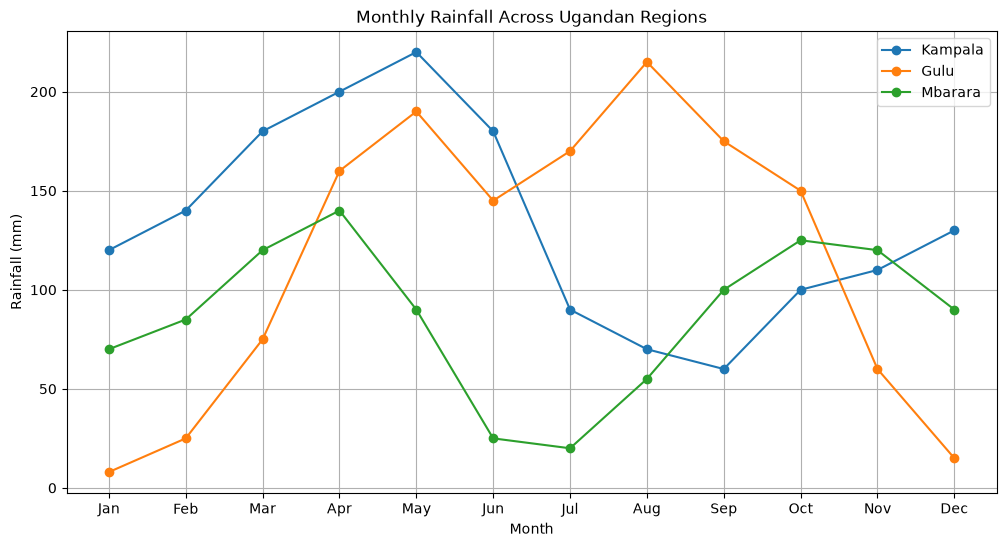

In [9]:
#visual, a line chart
plt.figure(figsize=(12, 6))
plt.plot(months,Kampala, marker="o",label="Kampala")
plt.plot( months,Gulu,marker="o",label="Gulu")
plt.plot(months, Mbarara,marker="o",label="Mbarara")
plt.xlabel("Month")
plt.ylabel("Rainfall (mm)")
plt.title("Monthly Rainfall Across Ugandan Regions")

plt.legend()
plt.grid(True)
plt.show()


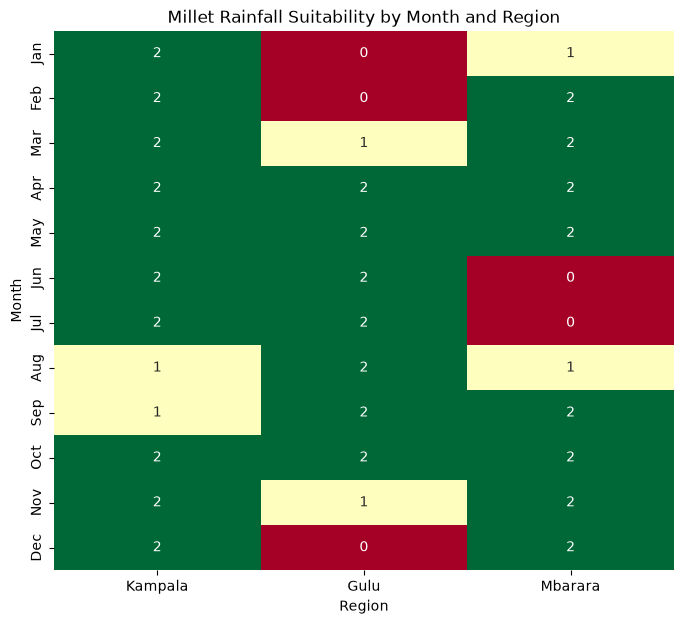

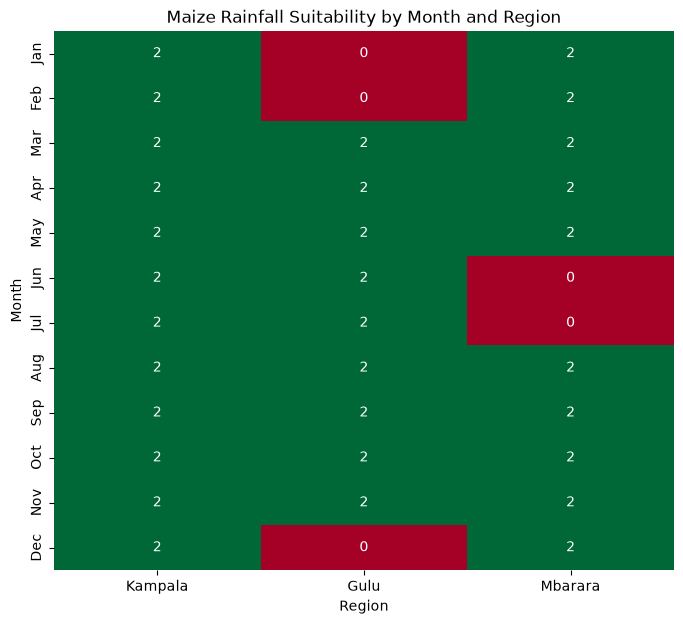

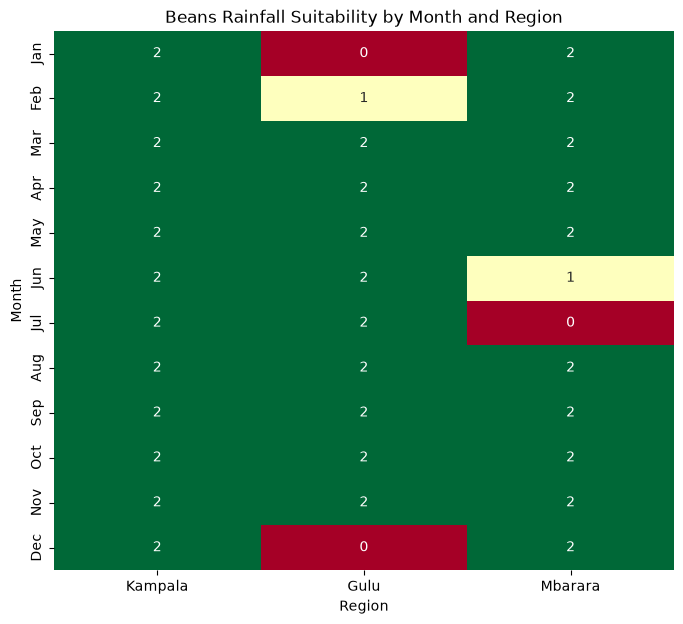

In [10]:
#heatnap
def suitability_score(crop, rainfall):
    if rainfall < crop.minimum:
        return 0      # Drought risk
    elif rainfall > crop.maximum:
        return 2       # Waterlogging risk
    else:
        return 1       # Good
def best_crop_classification(rainfall):
          results = []
          for crop in [maize, beans, millet]:
           score = suitability_score(crop,rainfall)
           results.append(score)
          return results
millet_scores = pd.DataFrame(
    {region_name: [suitability_score(millet,rainfall)for rainfall in rainfall_values] for region_name, rainfall_values in regions_data.items()},index=months)
plt.figure(figsize=(8, 7))
sns.heatmap(millet_scores,annot=True,cmap="RdYlGn",cbar=False)
plt.title("Millet Rainfall Suitability by Month and Region")
plt.xlabel("Region")
plt.ylabel("Month")
plt.show()

maize_scores = pd.DataFrame(
    {region_name: [suitability_score(maize,rainfall)for rainfall in rainfall_values] for region_name, rainfall_values in regions_data.items()},index=months)
plt.figure(figsize=(8, 7))
sns.heatmap(maize_scores,annot=True, cmap="RdYlGn",cbar=False)
plt.title("Maize Rainfall Suitability by Month and Region")
plt.xlabel("Region")
plt.ylabel("Month")
plt.show()

beans_scores = pd.DataFrame(
    {region_name: [suitability_score(beans,rainfall)for rainfall in rainfall_values] for region_name, rainfall_values in regions_data.items()},index=months)
plt.figure(figsize=(8, 7))
sns.heatmap( beans_scores,annot=True,cmap="RdYlGn",cbar=False)
plt.title("Beans Rainfall Suitability by Month and Region")
plt.xlabel("Region")
plt.ylabel("Month")
plt.show()